# Build Forcing Validation - Humidity and Pressure
- Tony Grove

NLDAS and the model use specific humidity, but the GAMUT site has relative humidity. In order to compare the two, I need to assess the specific humidity in the context of both temperature and pressure. This notebook assesses all the components.

In [1]:
%matplotlib ipympl
import pandas as pd
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from buildforcing.datasets import PNNLSnotel
import os

I created the Tony Grove RS forcing for 2015-10-01 to 2016-10-01 using BuildForcing v0.4.0, but passed the NLDAS data unchanged, except for the temperature data, which was corrected.

In [2]:
# Run parameters
site = 'Tony Grove RS'
latitude = 41.89
longitude = -111.57
start_date = '20151001'
end_date = '20161001'
buildforcing_version = 'v0.4.0'
downscale_settings = 's00000000'  #Still experimental, zeros indicate no downscaling
#environment = '/home/chriscox/Data/'
environment = 'C:/Users/clmbn/NMT_PhD/data/' # Windows

### Load datasets

In [3]:
# Load the forcing and NLDAS datasets
sitename = site.replace(' ', '').lower()
forcing = xr.open_dataset(os.path.join(environment, 'forcing', f'{sitename}_{start_date}_{end_date}_{downscale_settings}_{buildforcing_version}.nc'))

In [ ]:
nldas = xr.open_dataset(os.path.join(environment, 'nldas', f'NLDAS_{latitude}_{longitude}_{start_date}_{end_date}.nc'))

In [ ]:
snotel = PNNLSnotel(site_name=site, storage_path=os.path.join(environment, 'snotel'))

In [4]:
forcing_Qair = forcing[['Qair','Psurf','Tair']].isel(latitude=0, longitude=0).to_dataframe()

# Localize the forcing data and convert to America/Denver timezone
forcing_Qair.index = forcing_Qair.index.tz_localize('UTC').tz_convert('America/Denver')

### GAMUT Data

In [5]:
gamut_st110 = pd.read_csv(
    os.path.join(environment, 'gamut/tonygrovers', f'LR_TG_C_AirTemp_ST110_Avg_SourceID_1_QC_1.csv'),
    skiprows=56
    )

# Create datetime index from LocalDateTime
gamut_st110.index = pd.DatetimeIndex(
    pd.to_datetime(gamut_st110['LocalDateTime'], format='%Y-%m-%d %H:%M:%S')
)

# I only need 2015-2016 data
gamut_st110 = gamut_st110.loc['2015-10-01':'2016-10-01']


In [6]:
gamut_hc2s3 = pd.read_csv(
    os.path.join(environment, 'gamut/tonygrovers', f'LR_TG_C_RH_HC2S3_SourceID_1_QC_1.csv'),
    skiprows=55
    )

# Create datetime index from LocalDateTime
gamut_hc2s3.index = pd.DatetimeIndex(
    pd.to_datetime(gamut_hc2s3['LocalDateTime'], format='%Y-%m-%d %H:%M:%S')
)
# I only need 2015-2016 data
gamut_hc2s3 = gamut_hc2s3.loc['2015-10-01':'2016-10-01']

In [7]:
# Load the pressure data from LR_TG_C_BP_Avg_SourceID_1_QC_1.csv
gamut_bp = pd.read_csv(
    os.path.join(environment, 'gamut/tonygrovers', f'LR_TG_C_BP_Avg_SourceID_1_QC_1.csv'),
    skiprows=55
    )

# Create datetime index from LocalDateTime
gamut_bp.index = pd.DatetimeIndex(
    pd.to_datetime(gamut_bp['LocalDateTime'], format='%Y-%m-%d %H:%M:%S')
)
# I only need 2015-2016 data
gamut_bp = gamut_bp.loc['2015-10-01':'2016-10-01']

In [8]:
# Combine the data into a single DataFrame
gamut_data = pd.merge(gamut_st110['AirTemp_ST110_Avg'],gamut_hc2s3['RH_HC2S3'], left_index=True, right_index=True)
gamut_data = gamut_data.join(gamut_bp['BP_Avg'], how='left')

# Change all -9999 to NaN
gamut_data = gamut_data.replace(-9999, np.nan)

# Localize the data to the timezone of the site. Note the gamut data has a constant UTC offset of -7 hours
gamut_data.index = gamut_data.index - pd.Timedelta(hours=7)
gamut_data.index = gamut_data.index.tz_localize('UTC').tz_convert('America/Denver')

#### Compare GAMUT and NLDAS pressure


In [9]:
forcing_Qair['Psurf_kPa'] = forcing_Qair['Psurf'] / 1000

<Axes: xlabel='LocalDateTime'>

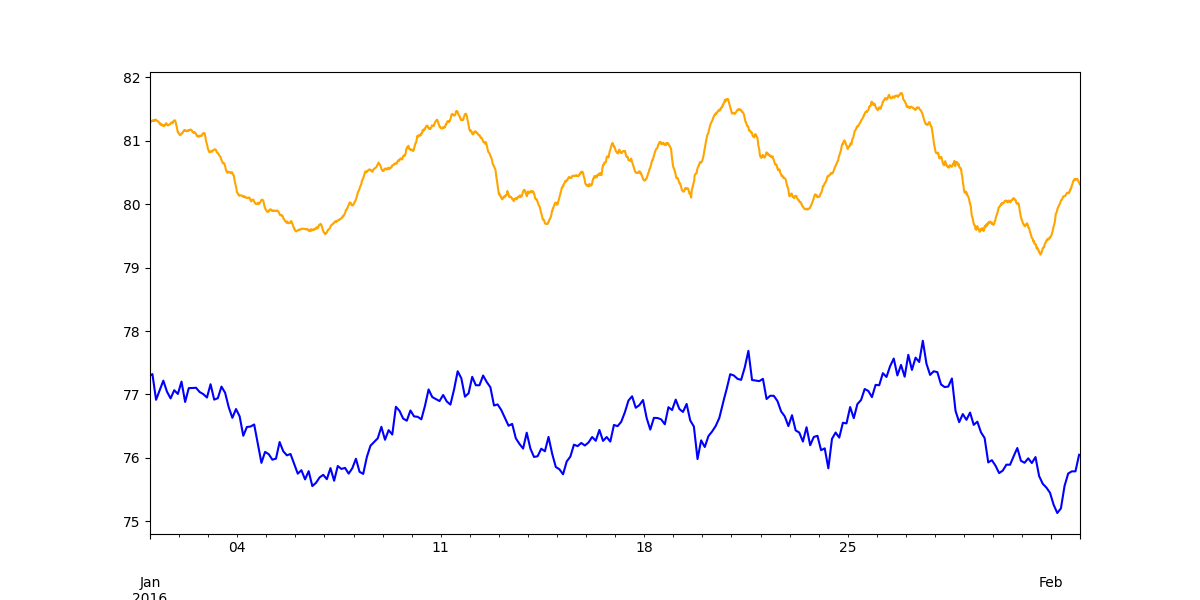

In [10]:
fig, ax = plt.subplots(figsize=(12, 6))
forcing_Qair.loc['20160101':'20160201','Psurf_kPa'].plot(ax=ax, label='Forcing Psurf (kPa)', color='blue')
gamut_data.loc['20160101':'20160201','BP_Avg'].plot(ax=ax, label='GAMUT BP (kPa)', color='orange')

Clearly, the NLDAS pressure is lower than the GAMUT pressure, probably because the NLDAS data is representative of a higher elevation.

### Try using MetPy


In [11]:
from metpy.calc import relative_humidity_from_specific_humidity
from metpy.units import units

#### Calculate Specific Humidity
This will compare specific humidity calculated from different datasets.

In [ ]:
# Get temperature and pressure from the gamut data
forcing_Qair = forcing_Qair.join(gamut_data['BP_Avg'], how='left')
forcing_Qair = forcing_Qair.join(gamut_data['AirTemp_ST110_Avg'], how='left')

In [12]:
rh_nldas = relative_humidity_from_specific_humidity(
    temperature=forcing_Qair['Tair'].values * units.degK,
    pressure=forcing_Qair['Psurf'].values * units.Pa,
    specific_humidity=forcing_Qair['Qair'].values
).to('percent')

forcing_Qair['RH'] = rh_nldas.magnitude

In [14]:
# Merge in gamut data so that RH can be calculated from the gamut data
forcing_gamut = pd.merge(forcing_Qair['Qair'], gamut_data, how='left', left_index=True, right_index=True)

In [15]:
forcing_gamut['RH'] = relative_humidity_from_specific_humidity(
    temperature=forcing_gamut['AirTemp_ST110_Avg'].values * units.degC,
    pressure=forcing_gamut['BP_Avg'].values * units.kPa,
    specific_humidity=forcing_gamut['Qair'].values
).to('percent').magnitude

### Calculate saturated specific humidity
In order to compare specific humidity to the GAMUT station, I use the HC2S3 sensor at the station. If I remember correctly, this sensor had an issue where it was getting solar heating, so readings my not be as accurate as they should be. The station measures % relative humidity with respect to vapor pressure. Barry and Chorley show that specific humidity $q$ relative to saturation $q/q_s$ should be less than relative humidity, so I will use that as a first point of analysis.

Per a source online that looked legit:
$$q_s \approx \frac{\epsilon e_s}{P}$$

Where $\epsilon$ is the ratio of wet/dry gas constants (0.622) So I need pressure and temperature (using ST110 thermister) to calculate saturation vapor pressure. I will use the following equation for saturation vapor pressure (wikipedia):
$$e_s = 6.11 \exp\left(\frac{17.27 T}{T + 237.3}\right)$$

Where $T$ is in Celsius and $e_s$ is in kPa.

#### Note
When I did this below, I somehow missed a factor of 10, otherwise the calculations below match metpy

In [ ]:
gamut_data['es'] = 6.11 * np.exp((17.27 * gamut_data['AirTemp_ST110_Avg']) / (gamut_data['AirTemp_ST110_Avg'] + 237.3))

In [ ]:
gamut_data['qs'] = (0.622 * gamut_data['es']) / gamut_data['BP_Avg'] 

In [ ]:
forcing_Qair = forcing_Qair.join(gamut_data['qs'], how='left')

In [ ]:
forcing_Qair['RH'] = (forcing_Qair['Qair'] / forcing_Qair['qs'])*100

## Comparisons

<Axes: xlabel='LocalDateTime'>

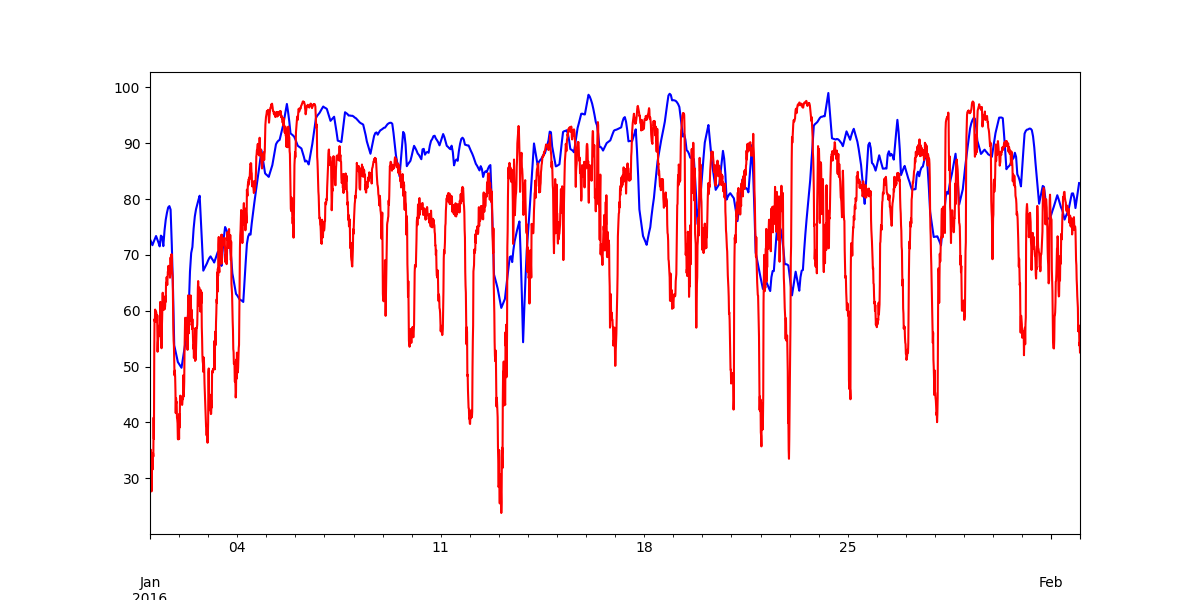

In [13]:
# Plot Tair and compare to ST110 data
fig, ax = plt.subplots(figsize=(12, 6))
forcing_Qair.loc['20160101':'20160201','RH'].plot(ax=ax, label='Qair_RH', color='blue')
gamut_data.loc['20160101':'20160201','RH_HC2S3'].plot(ax=ax, label='GAMUT_RH', color='red')

The daily trends are roughly the same, but the NLDAS RH has much less variability, probably because the temperature cycle is much more muted.

<Axes: xlabel='LocalDateTime'>

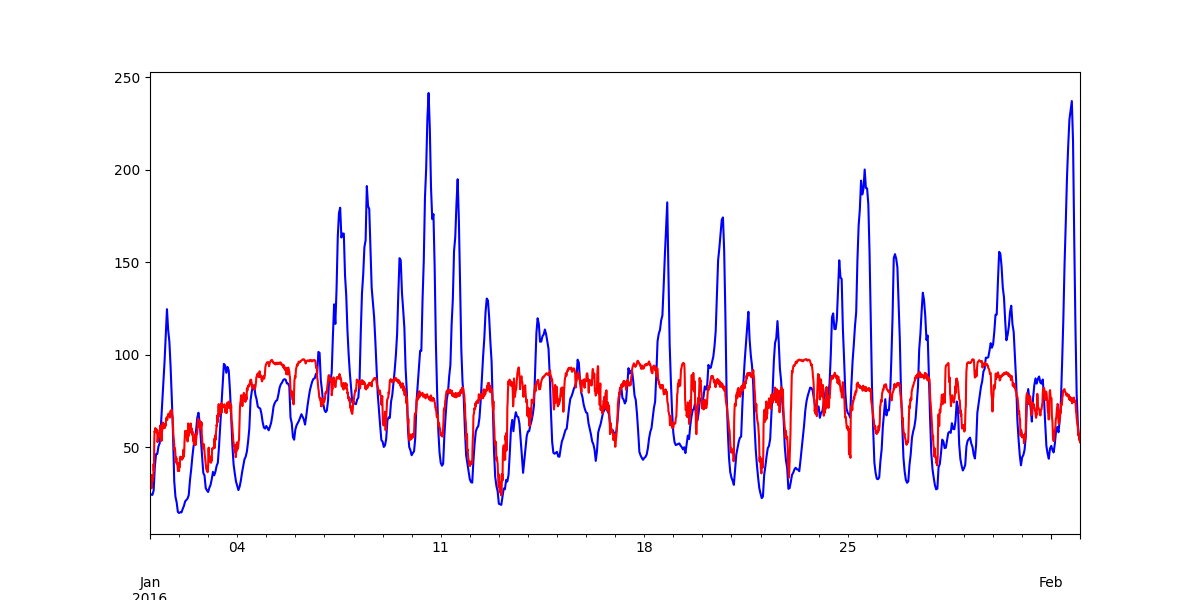

In [16]:
# This plot uses RH calculated from the Qair and RH from the GAMUT data
fig, ax = plt.subplots(figsize=(12, 6))
forcing_gamut.loc['20160101':'20160201','RH'].plot(ax=ax, label='Qair_RH', color='blue')
gamut_data.loc['20160101':'20160201','RH_HC2S3'].plot(ax=ax, label='GAMUT_RH', color='red')

#